In [1]:
import os, sys, json, math, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support, classification_report
from scipy.stats import chi2

warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130 | GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [2]:
PROJECT_DIR = os.path.abspath('.')                      # EmoSense folder (POSTER++ code + pretrained weights)
ROOT = os.path.dirname(PROJECT_DIR)
TRAIN_DIR = os.path.join(ROOT, 'raf_raw', 'DATASET', 'train')
TEST_DIR = os.path.join(ROOT, 'raf_raw', 'DATASET', 'test')
RUN_DIR = os.path.join(ROOT, 'runs', 'poster_improved')
POSTER_CKPT = os.path.join(PROJECT_DIR, 'best_50ep.pth')                         # POSTER++ trained for 25 epochs
os.makedirs(RUN_DIR, exist_ok=True)
sys.path.insert(0, PROJECT_DIR)

EMOTIONS = ['Surprise', 'Fear', 'Disgust', 'Happy', 'Sad', 'Angry', 'Neutral']
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

CFG = dict(epochs=25, batch_size=64, lr=1e-5, warmup_epochs=1, min_lr_ratio=0.01, weight_decay=1e-4,
           sam_rho=0.05, label_smoothing=0.1, vit_drop_path=0.1, erase_max=0.25,
           val_fraction=0.1, seed=42, num_workers=4, use_amp=True)
pd.DataFrame(CFG.items(), columns=['Setting', 'Value']).set_index('Setting').T

Setting,epochs,batch_size,lr,warmup_epochs,min_lr_ratio,weight_decay,sam_rho,label_smoothing,vit_drop_path,erase_max,val_fraction,seed,num_workers,use_amp
Value,25,64,0.00001,1,0.01,0.0001,0.05,0.1,0.1,0.25,0.1,42,4,True


In [3]:
full_train = datasets.ImageFolder(TRAIN_DIR)
test_raw = datasets.ImageFolder(TEST_DIR)
labels_all = np.array(full_train.targets)

# 10% of train held out for choosing the best epoch, test is used only at the end
train_idx, val_idx = train_test_split(np.arange(len(labels_all)), test_size=CFG['val_fraction'],
                                      stratify=labels_all, random_state=CFG['seed'])
train_labels = labels_all[train_idx]
class_counts = np.bincount(train_labels, minlength=7)
train_eval_idx, _ = train_test_split(train_idx, train_size=len(val_idx), stratify=train_labels,
                                     random_state=CFG['seed'])

pd.DataFrame({'Train': class_counts, 'Validation': np.bincount(labels_all[val_idx], minlength=7),
              'Test': np.bincount(test_raw.targets, minlength=7)}, index=EMOTIONS).T

,Surprise,Fear,Disgust,Happy,Sad,Angry,Neutral
Train,1161,253,645,4295,1784,634,2271
Validation,129,28,72,477,198,71,253
Test,329,74,160,1185,478,162,680


In [4]:
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply([transforms.RandomRotation(5), transforms.ColorJitter(brightness=0.2, contrast=0.2)], p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(scale=(0.02, CFG['erase_max'])),
])
eval_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

g = torch.Generator().manual_seed(CFG['seed'])
sampler = data.WeightedRandomSampler(torch.as_tensor(1.0 / class_counts[train_labels], dtype=torch.double),
                                     num_samples=len(train_idx), replacement=True, generator=g)   # class-balanced
kw = dict(batch_size=CFG['batch_size'], num_workers=CFG['num_workers'], pin_memory=True, persistent_workers=True)
train_loader = data.DataLoader(data.Subset(datasets.ImageFolder(TRAIN_DIR, train_tf), train_idx),
                               sampler=sampler, drop_last=True, **kw)
train_eval_loader = data.DataLoader(data.Subset(datasets.ImageFolder(TRAIN_DIR, eval_tf), train_eval_idx), **kw)
val_loader = data.DataLoader(data.Subset(datasets.ImageFolder(TRAIN_DIR, eval_tf), val_idx), **kw)
test_loader = data.DataLoader(datasets.ImageFolder(TEST_DIR, eval_tf), **kw)
print(f'Train {len(train_idx)} | Val {len(val_idx)} | Test {len(test_raw)}')

Train 11043 | Val 1228 | Test 3068


In [5]:
os.chdir(PROJECT_DIR)          # POSTER++ loads ./models/pretrain/*.pth
from models.PosterV2_7cls import pyramid_trans_expr2
from models.vit_model import VisionTransformer


class EmoSenseNet(pyramid_trans_expr2):
    # same POSTER++ network, final ViT rebuilt with drop path 0.1
    def __init__(self, drop_path=0.1):
        super().__init__(img_size=224, num_classes=7)
        self.VIT = VisionTransformer(in_c=147, depth=2, embed_dim=768, num_classes=7, drop_path_ratio=drop_path)


def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6, sum(p.numel() for p in m.parameters() if p.requires_grad) / 1e6

In [6]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def lr_factor(step, iters):
    warm, total = CFG['warmup_epochs'] * iters, CFG['epochs'] * iters
    if step < warm:
        return (step + 1) / warm
    t = min((step - warm) / max(1, total - warm), 1.0)
    return CFG['min_lr_ratio'] + (1 - CFG['min_lr_ratio']) * 0.5 * (1 + math.cos(math.pi * t))


def forward_loss(model, x, y, criterion):
    with torch.autocast('cuda', dtype=torch.float16, enabled=CFG['use_amp']):
        logits = model(x)
    return logits.float(), criterion(logits.float(), y)


def train_step(model, x, y, criterion, optimizer, scaler, params):
    optimizer.zero_grad(set_to_none=True)
    logits, loss = forward_loss(model, x, y, criterion)
    scaler.scale(loss).backward()
    # SAM: step to w + rho*g/|g|, take the gradient there, then step back
    norm = torch.norm(torch.stack([p.grad.float().norm(2) for p in params if p.grad is not None]), 2)
    eps = []
    with torch.no_grad():
        for p in params:
            e = None if p.grad is None or not torch.isfinite(norm) else p.grad.float() * (CFG['sam_rho'] / (norm + 1e-12))
            if e is not None:
                p.add_(e)
            eps.append(e)
    optimizer.zero_grad(set_to_none=True)
    _, loss2 = forward_loss(model, x, y, criterion)
    scaler.scale(loss2).backward()
    with torch.no_grad():
        for p, e in zip(params, eps):
            if e is not None:
                p.sub_(e)
    scaler.step(optimizer)
    scaler.update()
    return logits.detach(), loss.detach()


def metrics_from(preds, labels):
    cm = confusion_matrix(labels, preds, labels=np.arange(7))
    per_class = cm.diagonal() / cm.sum(1) * 100
    prec, rec, f1, _ = precision_recall_fscore_support(labels, preds, labels=np.arange(7), zero_division=0)
    return {'accuracy': float((preds == labels).mean() * 100), 'mean_class_accuracy': float(per_class.mean()),
            'macro_f1': float(f1.mean() * 100), 'per_class': dict(zip(EMOTIONS, per_class.round(4).tolist())),
            'precision': dict(zip(EMOTIONS, (prec * 100).round(4).tolist())),
            'f1': dict(zip(EMOTIONS, (f1 * 100).round(4).tolist())), 'confusion_matrix': cm.tolist()}


@torch.no_grad()
def predict(model, loader, amp=True):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        with torch.autocast('cuda', dtype=torch.float16, enabled=amp):
            preds.append(model(x.to(device, non_blocking=True)).float().argmax(1).cpu())
        labels.append(y)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()


def evaluate(model, loader, amp=True):
    return metrics_from(*predict(model, loader, amp))

In [7]:
def train():
    seed_everything(CFG['seed'])
    model = EmoSenseNet(CFG['vit_drop_path']).to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])
    optimizer = torch.optim.Adam(params, lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: lr_factor(s, len(train_loader)))
    scaler = torch.amp.GradScaler('cuda', enabled=CFG['use_amp'])
    print('Parameters: %.1fM total, %.1fM trainable' % count_params(model))

    latest, best_path = os.path.join(RUN_DIR, 'latest.pth'), os.path.join(RUN_DIR, 'best.pth')
    start, best_val, history = 0, -1.0, []
    if os.path.isfile(latest):                     # resume if interrupted
        ck = torch.load(latest, map_location='cpu', weights_only=False)
        model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
        scheduler.load_state_dict(ck['scheduler']); scaler.load_state_dict(ck['scaler'])
        start, best_val, history = ck['epoch'] + 1, ck['best_val'], ck['history']
        print(f'Resumed after epoch {start}')

    for epoch in range(start, CFG['epochs']):
        t0 = time.time()
        model.train()
        loss_sum, seen = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            _, loss = train_step(model, x, y, criterion, optimizer, scaler, params)
            scheduler.step()
            loss_sum += loss.item() * y.size(0); seen += y.size(0)
        tr = evaluate(model, train_eval_loader)['accuracy']
        val = evaluate(model, val_loader)
        history.append({'epoch': epoch + 1, 'train_loss': loss_sum / seen, 'train_acc': tr, 'val_acc': val['accuracy'],
                        'val_mean_class': val['mean_class_accuracy'], 'minutes': (time.time() - t0) / 60})
        if val['accuracy'] > best_val:
            best_val = val['accuracy']
            torch.save({'model': model.state_dict(), 'epoch': epoch + 1, 'val': val}, best_path)
        torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(),
                    'scaler': scaler.state_dict(), 'epoch': epoch, 'best_val': best_val, 'history': history}, latest)
        pd.DataFrame(history).to_csv(os.path.join(RUN_DIR, 'history.csv'), index=False)
        h = history[-1]
        print(f"Epoch {h['epoch']:2d}/{CFG['epochs']} | loss {h['train_loss']:.4f} | train {h['train_acc']:.2f}% | "
              f"val {h['val_acc']:.2f}% | best val {best_val:.2f}% | {h['minutes']:.1f} min")
    return model


model = train()

load_weight 304


Parameters: 58.3M total, 57.3M trainable


Epoch  1/25 | loss 1.8327 | train 56.43% | val 56.11% | best val 56.11% | 2.7 min


Epoch  2/25 | loss 1.0948 | train 80.54% | val 78.75% | best val 78.75% | 1.8 min


Epoch  3/25 | loss 0.8563 | train 89.01% | val 83.96% | best val 83.96% | 1.8 min


Epoch  4/25 | loss 0.7693 | train 89.50% | val 81.68% | best val 83.96% | 1.8 min


... (17 outputs left out)

Epoch 22/25 | loss 0.5210 | train 98.53% | val 90.23% | best val 90.72% | 1.8 min


Epoch 23/25 | loss 0.5191 | train 98.53% | val 90.64% | best val 90.72% | 1.9 min


Epoch 24/25 | loss 0.5127 | train 98.70% | val 90.80% | best val 90.80% | 1.8 min


Epoch 25/25 | loss 0.5190 | train 98.70% | val 90.39% | best val 90.80% | 1.8 min


In [8]:
def load_poster(path):
    m = torch.nn.DataParallel(pyramid_trans_expr2(img_size=224, num_classes=7)).to(device)
    ck = torch.load(path, map_location='cpu', weights_only=False)
    m.load_state_dict(ck['state_dict'])
    return m, ck['epoch'] + 1


def load_emosense(path):
    m = EmoSenseNet(CFG['vit_drop_path']).to(device)
    ck = torch.load(path, map_location='cpu', weights_only=False)
    m.load_state_dict(ck['model'])
    return m, ck['epoch']


POSTER, EMOSENSE = 'POSTER++ (25 epochs)', 'EmoSense (25 epochs)'
results, preds = {}, {}
for name, loader_fn, path, amp in [(POSTER, load_poster, POSTER_CKPT, False),
                                   (EMOSENSE, load_emosense, os.path.join(RUN_DIR, 'best.pth'), True)]:
    m, ep = loader_fn(path)
    p, y_test = predict(m, test_loader, amp)
    preds[name], results[name] = p, metrics_from(p, y_test)
    print(f"{name}: checkpoint epoch {ep} | accuracy {results[name]['accuracy']:.2f}% | macro-F1 {results[name]['macro_f1']:.2f}%")
    del m; torch.cuda.empty_cache()

json.dump(results, open(os.path.join(RUN_DIR, 'test_results.json'), 'w'), indent=2)

load_weight 304


POSTER++ (25 epochs): checkpoint epoch 18 | accuracy 89.15% | macro-F1 84.06%


load_weight 304


EmoSense (25 epochs): checkpoint epoch 24 | accuracy 91.23% | macro-F1 87.13%


In [9]:
def row(m):
    return {'Accuracy': m['accuracy'], 'Mean class acc.': m['mean_class_accuracy'], 'Macro-F1': m['macro_f1'], **m['per_class']}

table = pd.DataFrame({k: row(v) for k, v in results.items()}).T
table.loc['Improvement'] = table.loc[EMOSENSE] - table.loc[POSTER]
table = table.round(2)
table.to_csv(os.path.join(RUN_DIR, 'results_table.csv'))
table

,Accuracy,Mean class acc.,Macro-F1,Surprise,Fear,Disgust,Happy,Sad,Angry,Neutral
POSTER++ (25 epochs),89.15,85.59,84.06,88.75,72.97,84.38,93.08,82.01,87.04,90.88
EmoSense (25 epochs),91.23,86.71,87.13,90.27,71.62,80.00,94.94,89.33,88.89,91.91
Improvement,2.09,1.12,3.07,1.52,-1.35,-4.38,1.86,7.32,1.85,1.03


In [10]:
# per-class precision and F1
pf = pd.DataFrame({'Precision POSTER++': results[POSTER]['precision'], 'Precision EmoSense': results[EMOSENSE]['precision'],
                   'F1 POSTER++': results[POSTER]['f1'], 'F1 EmoSense': results[EMOSENSE]['f1']})
pf['F1 change'] = pf['F1 EmoSense'] - pf['F1 POSTER++']
pf.loc['Macro average'] = pf.mean()
pf.round(2)

,Precision POSTER++,Precision EmoSense,F1 POSTER++,F1 EmoSense,F1 change
Surprise,87.69,87.61,88.22,88.92,0.70
Fear,72.97,84.13,72.97,77.37,4.40
Disgust,62.21,79.50,71.62,79.75,8.13
Happy,98.92,97.91,95.91,96.40,0.49
Sad,87.89,88.59,84.85,88.96,4.11
Angry,85.98,88.34,86.50,88.62,2.11
Neutral,85.95,87.90,88.35,89.86,1.51
Macro average,83.09,87.71,84.06,87.13,3.07


In [11]:
print(f'Per-class report: {EMOSENSE}')
print(classification_report(y_test, preds[EMOSENSE], target_names=EMOTIONS, digits=3))

Per-class report: EmoSense (25 epochs)
              precision    recall  f1-score   support

    Surprise      0.876     0.903     0.889       329
        Fear      0.841     0.716     0.774        74
     Disgust      0.795     0.800     0.798       160
       Happy      0.979     0.949     0.964      1185
         Sad      0.886     0.893     0.890       478
       Angry      0.883     0.889     0.886       162
     Neutral      0.879     0.919     0.899       680

    accuracy                          0.912      3068
   macro avg      0.877     0.867     0.871      3068
weighted avg      0.913     0.912     0.913      3068



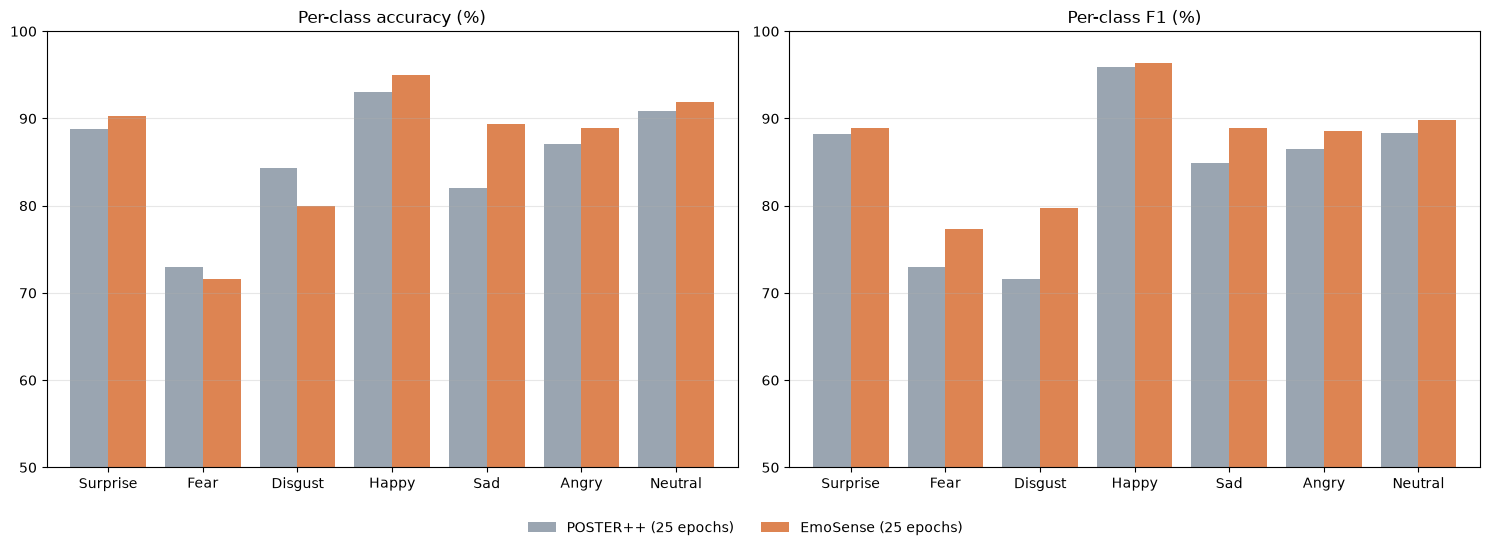

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
acc_df = pd.DataFrame({k: v['per_class'] for k, v in results.items()})
f1_df = pd.DataFrame({k: v['f1'] for k, v in results.items()})
for ax, df, title in [(axes[0], acc_df, 'Per-class accuracy (%)'), (axes[1], f1_df, 'Per-class F1 (%)')]:
    df.plot(kind='bar', ax=ax, width=0.8, color=['#9aa5b1', '#dd8452'], legend=False)
    ax.set(title=title, ylim=(50, 100)); ax.tick_params(axis='x', rotation=0); ax.grid(axis='y', alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.savefig(os.path.join(RUN_DIR, 'per_class.png'), dpi=200); plt.show()

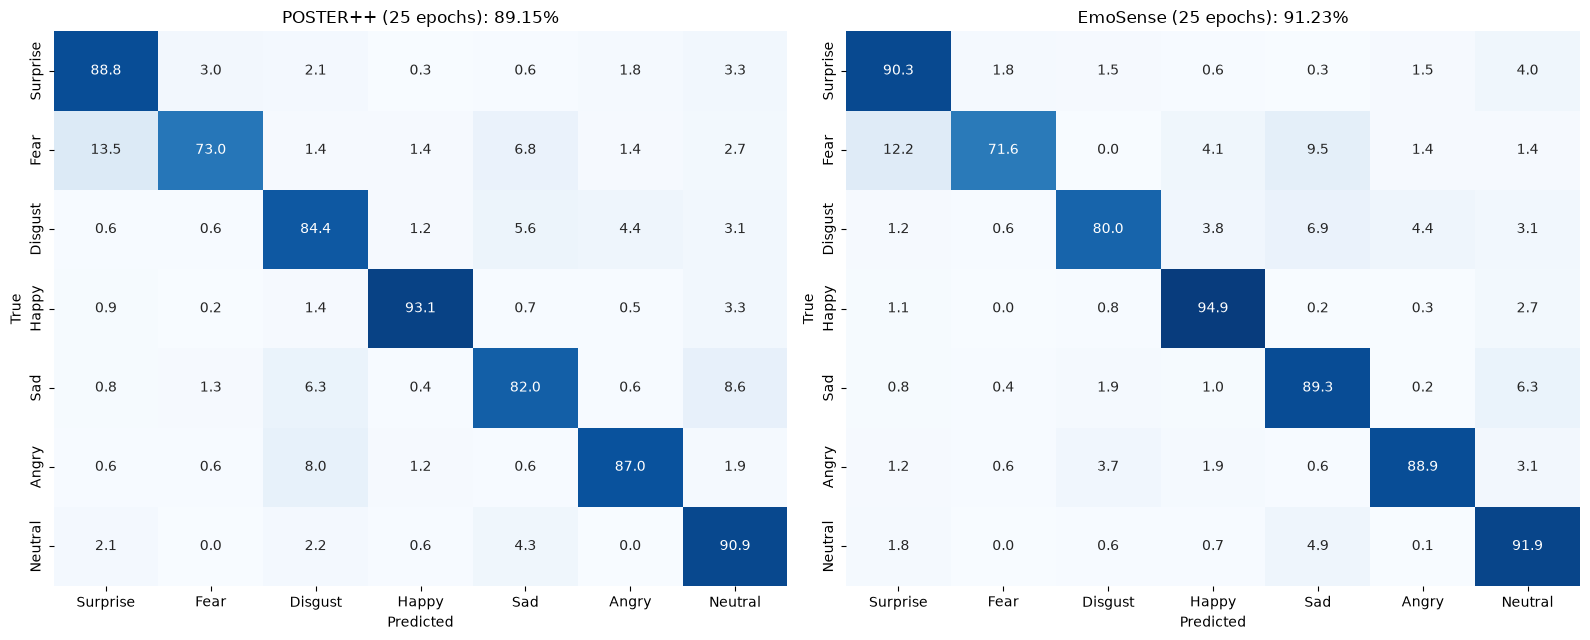

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, name in zip(axes, [POSTER, EMOSENSE]):
    cm = np.array(results[name]['confusion_matrix'], dtype=float)
    sns.heatmap(cm / cm.sum(1, keepdims=True) * 100, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100, cbar=False,
                xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=ax)
    ax.set(title=f"{name}: {results[name]['accuracy']:.2f}%", xlabel='Predicted', ylabel='True')
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, 'confusion_matrices.png'), dpi=200); plt.show()

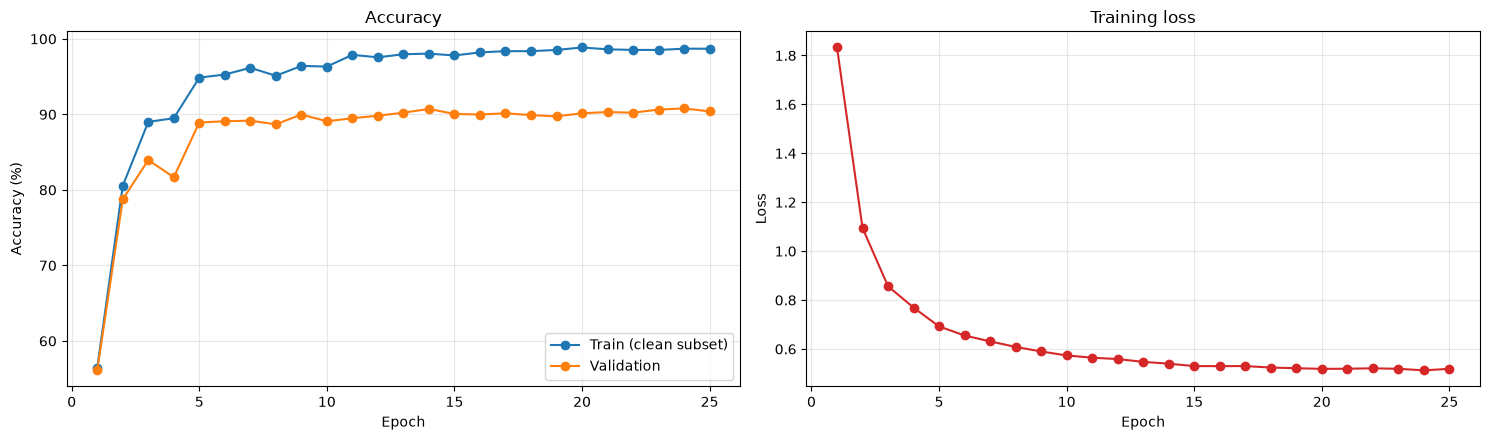

In [14]:
h = pd.read_csv(os.path.join(RUN_DIR, 'history.csv'))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
ax1.plot(h['epoch'], h['train_acc'], marker='o', label='Train (clean subset)')
ax1.plot(h['epoch'], h['val_acc'], marker='o', label='Validation')
ax1.set(xlabel='Epoch', ylabel='Accuracy (%)', title='Accuracy')
ax2.plot(h['epoch'], h['train_loss'], marker='o', color='C3')
ax2.set(xlabel='Epoch', ylabel='Loss', title='Training loss')
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
ax1.legend()
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, 'training_curves.png'), dpi=200); plt.show()

In [15]:
# McNemar test on the same test images
def mcnemar(ref, new):
    ok_r, ok_n = preds[ref] == y_test, preds[new] == y_test
    b, c = int((ok_r & ~ok_n).sum()), int((~ok_r & ok_n).sum())
    return c, b, chi2.sf((abs(b - c) - 1) ** 2 / (b + c), df=1)

fixed, broken, p = mcnemar(POSTER, EMOSENSE)
print(f'Images fixed by EmoSense: {fixed} | broken: {broken} | p = {p:.2e}')

Images fixed by EmoSense: 111 | broken: 47 | p = 5.39e-07
